# Marketing Campaign A/B Test: Did the Ads Work?

**Author:** Daljeet Kaur
**Tools:** Python (pandas, NumPy, SciPy, matplotlib)
**Dataset:** [Marketing A/B Testing](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) (Kaggle) — 588,101 users

## Business context
A company ran an ad campaign. Most users (the **test group, "ad"**) saw the product ad. A small **control group ("psa")** saw a public-service announcement in the same slots instead. That way, any difference in purchases can be credited to the ad itself, not to timing or seasonality.

## Objectives
1. **Primary:** Did the ad campaign increase the conversion rate, and is the lift statistically significant?
2. How many conversions did the campaign *add* (incremental impact)?
3. **Secondary:** When and at what ad frequency is the campaign most effective, so the budget can be reallocated?

**Hypotheses (two-sided, α = 0.05)**
H₀: conversion rate (ad) = conversion rate (psa)
H₁: conversion rate (ad) ≠ conversion rate (psa)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
AD, PSA, GREY = "#2563eb", "#9ca3af", "#6b7280"
IMG_DIR, RESULTS_DIR = "../images", "../results"
rng = np.random.default_rng(42)

## 1. Load and clean

In [2]:
raw = pd.read_csv("../data/marketing_AB.csv", index_col=0)
df = raw.rename(columns=lambda c: c.strip().replace(" ", "_"))
df["converted"] = df["converted"].astype(int)
print(df.shape)
df.head()

(588101, 6)


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


In [3]:
checks = {
    "rows": len(df),
    "unique users": df["user_id"].nunique(),
    "missing values": int(df.isna().sum().sum()),
    "groups": sorted(df["test_group"].unique()),
    "total_ads min / max": (df["total_ads"].min(), df["total_ads"].max()),
}
checks

{'rows': 588101,
 'unique users': 588101,
 'missing values': 0,
 'groups': ['ad', 'psa'],
 'total_ads min / max': (np.int64(1), np.int64(2065))}

No missing values and no duplicate users, so every row is one user in exactly one group.

## 2. Sanity checks before testing
A test result is only trustworthy if the two groups were treated the same apart from the ad. Three checks:
1. **Split:** the 96/4 split is by design (the company limited how many people it "lost" to the PSA), so no sample-ratio problem.
2. **Exposure:** did both groups see a similar number of impressions?
3. **Timing:** did both groups see their impressions on similar days and hours?

In [4]:
summary = (df.groupby("test_group")
             .agg(users=("user_id", "size"),
                  conversions=("converted", "sum"),
                  conversion_rate=("converted", "mean"),
                  mean_ads=("total_ads", "mean"),
                  median_ads=("total_ads", "median")))
summary["share_of_users"] = summary["users"] / summary["users"].sum()
summary.round(4)

,users,conversions,conversion_rate,mean_ads,median_ads,share_of_users
test_group,,,,,,
ad,564577,14423,0.0255,24.8234,13.0,0.96
psa,23524,420,0.0179,24.7611,12.0,0.04


In [5]:
# Exposure balance: means are ~identical; with n = 588K even tiny differences test "significant",
# so judge balance by effect size (standardized mean difference), not the p-value.
ad_ads = df.loc[df.test_group == "ad", "total_ads"]
psa_ads = df.loc[df.test_group == "psa", "total_ads"]
smd = (ad_ads.mean() - psa_ads.mean()) / np.sqrt((ad_ads.var() + psa_ads.var()) / 2)
print(f"Mean impressions  ad={ad_ads.mean():.2f}  psa={psa_ads.mean():.2f}")
print(f"Standardized mean difference = {smd:.4f}  (|SMD| < 0.1 = balanced)")

# Timing balance: distribution of the user's peak-ad day across groups
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_mix = pd.crosstab(df.most_ads_day, df.test_group, normalize="columns").loc[day_order]
chi2, p_day, _, _ = stats.chi2_contingency(pd.crosstab(df.most_ads_day, df.test_group))
print(f"\nPeak-day mix differs slightly between groups (chi² p = {p_day:.1e}); max gap = "
      f"{(day_mix['ad'] - day_mix['psa']).abs().max():.1%} points")
(day_mix * 100).round(1)

Mean impressions  ad=24.82  psa=24.76
Standardized mean difference = 0.0014  (|SMD| < 0.1 = balanced)

Peak-day mix differs slightly between groups (chi² p = 4.8e-48); max gap = 2.6% points


test_group,ad,psa
most_ads_day,,
Monday,14.8,14.9
Tuesday,13.2,12.4
Wednesday,13.7,14.8
Thursday,14.0,16.6
Friday,15.7,16.2
Saturday,14.0,12.1
Sunday,14.6,13.0


Exposure is balanced (SMD ≈ 0). The peak-day mix differs by at most ~2.6 percentage points. To make sure this doesn't explain the result, Section 5 re-checks the lift **within each day**.

## 3. Primary test: two-proportion z-test

In [6]:
def two_proportion_ztest(x1, n1, x2, n2, alpha=0.05):
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se_pooled = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se_pooled
    p_value = 2 * stats.norm.sf(abs(z))
    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)   # unpooled SE for the CI
    zc = stats.norm.ppf(1 - alpha / 2)
    diff = p1 - p2
    return {"rate_ad": p1, "rate_psa": p2, "abs_lift": diff, "rel_lift": diff / p2,
            "ci_low": diff - zc * se_diff, "ci_high": diff + zc * se_diff,
            "z": z, "p_value": p_value}

s = summary
res = two_proportion_ztest(s.loc["ad", "conversions"], s.loc["ad", "users"],
                           s.loc["psa", "conversions"], s.loc["psa", "users"])
for k, v in res.items():
    print(f"{k:>9}: {v:.6f}" if k != "p_value" else f"{k:>9}: {v:.2e}")

  rate_ad: 0.025547
 rate_psa: 0.017854
 abs_lift: 0.007692
 rel_lift: 0.430851
   ci_low: 0.005951
  ci_high: 0.009434
        z: 7.370078
  p_value: 1.71e-13


In [7]:
# Cross-check with a chi-square test and a bootstrap CI for the relative lift
ct = pd.crosstab(df.test_group, df.converted)
chi2, p_chi, _, _ = stats.chi2_contingency(ct, correction=False)
print(f"Chi-square p-value: {p_chi:.2e}")

ad_conv = df.loc[df.test_group == "ad", "converted"].to_numpy()
psa_conv = df.loc[df.test_group == "psa", "converted"].to_numpy()
B = 2000
boot = np.empty(B)
for i in range(B):
    a = rng.binomial(len(ad_conv), ad_conv.mean()) / len(ad_conv)
    p = rng.binomial(len(psa_conv), psa_conv.mean()) / len(psa_conv)
    boot[i] = a / p - 1
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Relative lift: {res['rel_lift']:.1%}  (bootstrap 95% CI {lo:.1%} to {hi:.1%})")

Chi-square p-value: 1.71e-13
Relative lift: 43.1%  (bootstrap 95% CI 30.5% to 57.4%)


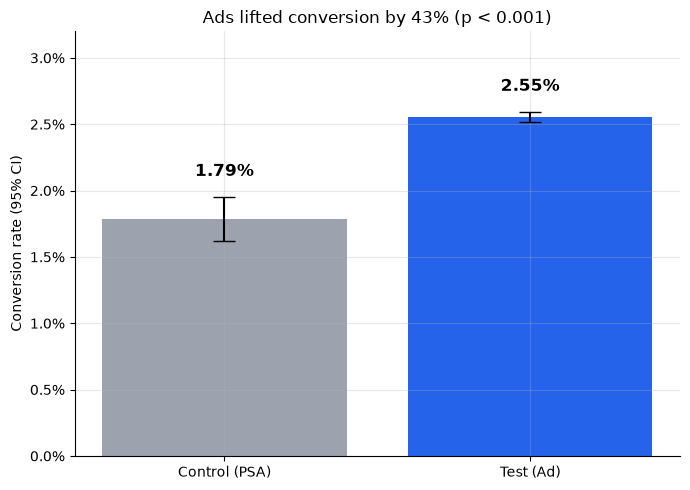

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
rates = [res["rate_psa"], res["rate_ad"]]
ci_half = [1.96 * np.sqrt(r * (1 - r) / n) for r, n in zip(rates, [s.loc["psa", "users"], s.loc["ad", "users"]])]
bars = ax.bar(["Control (PSA)", "Test (Ad)"], rates, yerr=ci_half, capsize=8, color=[PSA, AD])
ax.bar_label(bars, labels=[f"{r:.2%}" for r in rates], padding=12, fontsize=12, fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_ylim(0, 0.032)
ax.set_ylabel("Conversion rate (95% CI)")
ax.set_title(f"Ads lifted conversion by {res['rel_lift']:.0%} (p < 0.001)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/01_conversion_by_group.png", dpi=150)

**Result:** Reject H₀. The ad group converted at **2.55%** vs **1.79%** for the control. That is an absolute lift of **+0.77 percentage points** (95% CI roughly +0.6 to +0.9 pts) and a **relative lift of ~43%**, with **p ≈ 1.7 × 10⁻¹³**. The chi-square test and the bootstrap give the same answer.

## 4. Business impact: incremental conversions

In [9]:
n_ad = s.loc["ad", "users"]
incremental = n_ad * res["abs_lift"]
inc_lo, inc_hi = n_ad * res["ci_low"], n_ad * res["ci_high"]
share = incremental / s.loc["ad", "conversions"]
print(f"Conversions in ad group:            {s.loc['ad', 'conversions']:,}")
print(f"Expected without ads (PSA rate):    {n_ad * res['rate_psa']:,.0f}")
print(f"Incremental conversions from ads:   {incremental:,.0f}  (95% CI {inc_lo:,.0f} – {inc_hi:,.0f})")
print(f"Share of ad-group conversions caused by the ads: {share:.0%}")

Conversions in ad group:            14,423
Expected without ads (PSA rate):    10,080
Incremental conversions from ads:   4,343  (95% CI 3,360 – 5,326)
Share of ad-group conversions caused by the ads: 30%


About **4,300 of the 14,423 conversions (~30%)** in the ad group would not have happened without the ads. The other ~70% would have bought anyway. That gap matters when finance calculates the campaign's ROI: crediting every conversion to the ads would overstate the campaign's return about 3.3x.

## 5. Where do ads work best? (secondary analysis)
### 5a. Lift by peak-ad day (also a robustness check for the day-mix imbalance)

In [10]:
def lift_by(col, order=None):
    rows = []
    for key, g in df.groupby(col):
        a, p = g[g.test_group == "ad"], g[g.test_group == "psa"]
        r = two_proportion_ztest(a.converted.sum(), len(a), p.converted.sum(), len(p))
        rows.append({col: key, "users": len(g), "rate_ad": r["rate_ad"], "rate_psa": r["rate_psa"],
                     "abs_lift_pts": r["abs_lift"] * 100, "p_value": r["p_value"]})
    out = pd.DataFrame(rows).set_index(col)
    return out.loc[order] if order else out

by_day = lift_by("most_ads_day", day_order)
by_day.round(4)

,users,rate_ad,rate_psa,abs_lift_pts,p_value
most_ads_day,,,,,
Monday,87073,0.0332,0.0226,1.0683,0.0005
Tuesday,77479,0.0304,0.0144,1.5992,0.0000
Wednesday,80908,0.0254,0.0158,0.9597,0.0004
Thursday,82982,0.0216,0.0202,0.1407,0.5548
Friday,92608,0.0225,0.0163,0.6162,0.0116
Saturday,81660,0.0213,0.0140,0.7311,0.0075
Sunday,85391,0.0246,0.0206,0.4025,0.1572


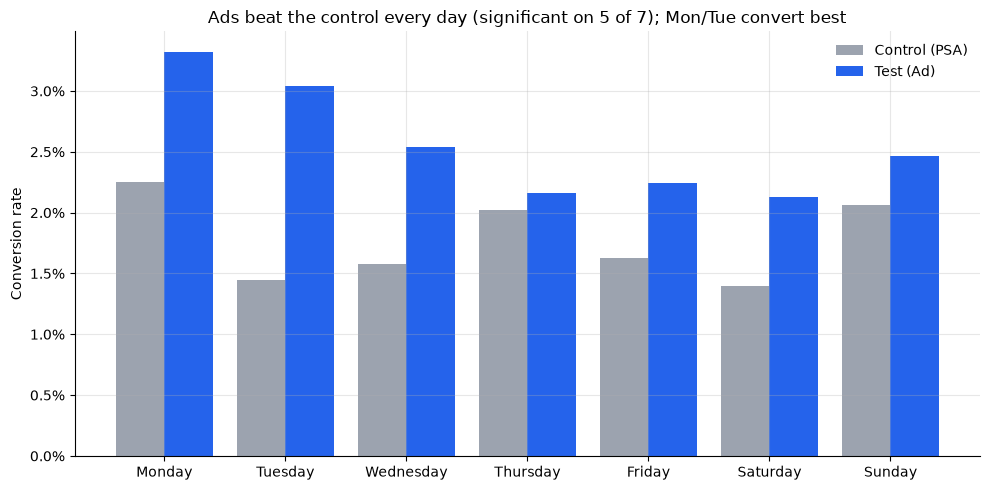

In [11]:
fig, ax = plt.subplots()
x = np.arange(len(by_day))
ax.bar(x - 0.2, by_day.rate_psa, 0.4, label="Control (PSA)", color=PSA)
ax.bar(x + 0.2, by_day.rate_ad, 0.4, label="Test (Ad)", color=AD)
ax.set_xticks(x, by_day.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_ylabel("Conversion rate")
ax.set_title("Ads beat the control every day (significant on 5 of 7); Mon/Tue convert best")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/02_conversion_by_day.png", dpi=150)

The ad group converts higher on all 7 days, and the gap is significant on 5 of them. Thursday and Sunday are not significant, partly because each day has only ~3,500 control users. So the overall lift is **not** caused by the slight day-mix difference. Monday (3.3%) and Tuesday (3.0%) are the strongest ad days, and Saturday and Thursday (~2.1%) are the weakest.

### 5b. Ad-group conversion by hour of day

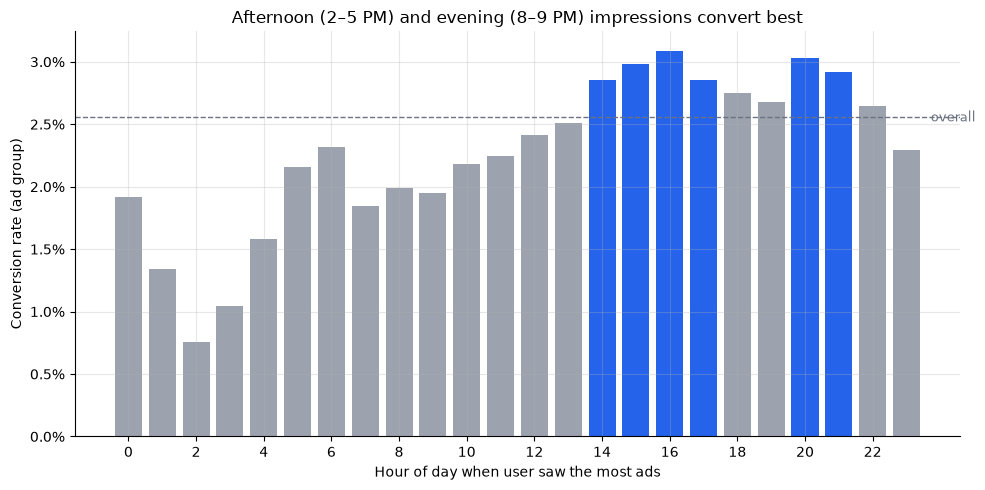

In [12]:
by_hour = (df[df.test_group == "ad"].groupby("most_ads_hour")
           .agg(users=("converted", "size"), conv_rate=("converted", "mean")))
fig, ax = plt.subplots()
colors = [AD if r >= 0.028 else PSA for r in by_hour.conv_rate]
ax.bar(by_hour.index, by_hour.conv_rate, color=colors)
ax.axhline(res["rate_ad"], color=GREY, ls="--", lw=1)
ax.text(23.6, res["rate_ad"], " overall", va="center", fontsize=9, color=GREY)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day when user saw the most ads")
ax.set_ylabel("Conversion rate (ad group)")
ax.set_title("Afternoon (2–5 PM) and evening (8–9 PM) impressions convert best")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/03_conversion_by_hour.png", dpi=150)

In [13]:
night = df[(df.test_group == "ad") & (df.most_ads_hour.between(1, 4))]
prime = df[(df.test_group == "ad") & (df.most_ads_hour.between(14, 21))]
print(f"1–4 AM conversion: {night.converted.mean():.2%} ({len(night):,} users)")
print(f"2–9 PM conversion: {prime.converted.mean():.2%} ({len(prime):,} users)")

1–4 AM conversion: 1.07% (13,051 users)
2–9 PM conversion: 2.90% (273,164 users)


### 5c. Ad frequency (dose–response)
More impressions go with higher conversion. This part is **observational**, though: heavy users both see more ads and buy more. So the honest comparison is the *gap between ad and PSA* in each exposure band.

In [13]:
bins = [0, 10, 25, 50, 100, 200, df.total_ads.max()]
labels = ["1–10", "11–25", "26–50", "51–100", "101–200", "200+"]
df["ads_band"] = pd.cut(df.total_ads, bins=bins, labels=labels)
by_band = lift_by("ads_band", labels)
by_band["rel_lift"] = by_band.rate_ad / by_band.rate_psa - 1
by_band.round(4)

,users,rate_ad,rate_psa,abs_lift_pts,p_value,rel_lift
ads_band,,,,,,
1–10,260775,0.0033,0.0040,-0.0732,0.1841,-0.1835
11–25,169247,0.0102,0.0100,0.0189,0.8849,0.0189
26–50,89013,0.0354,0.0266,0.8840,0.0070,0.3326
51–100,46002,0.1163,0.0577,5.8566,0.0000,1.0142
101–200,17112,0.1768,0.1064,7.0390,0.0000,0.6617
200+,5952,0.1558,0.1550,0.0739,0.9744,0.0048


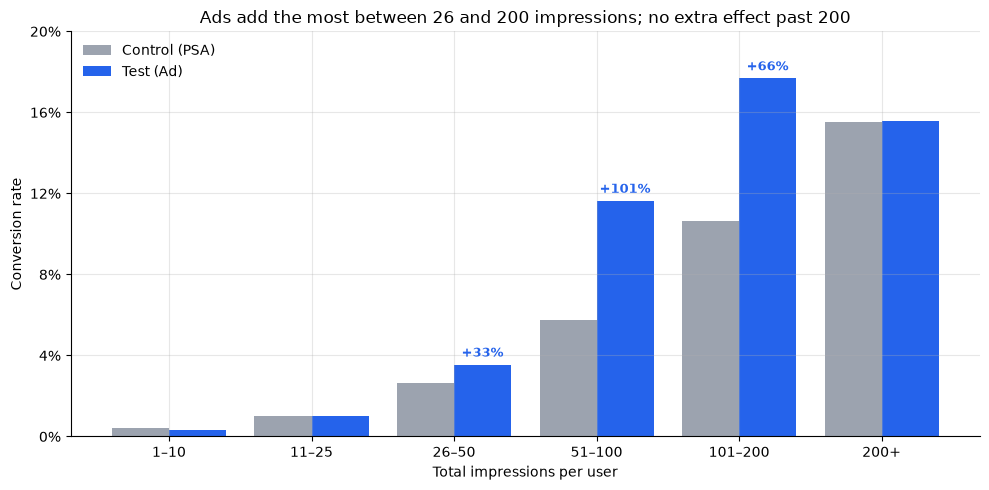

In [14]:
fig, ax = plt.subplots()
x = np.arange(len(by_band))
ax.bar(x - 0.2, by_band.rate_psa, 0.4, label="Control (PSA)", color=PSA)
ax.bar(x + 0.2, by_band.rate_ad, 0.4, label="Test (Ad)", color=AD)
for i, (r, p) in enumerate(zip(by_band.rel_lift, by_band.p_value)):
    if p < 0.05:
        ax.text(i + 0.2, by_band.rate_ad.iloc[i] + 0.004, f"+{r:.0%}", ha="center", fontsize=9, color=AD, fontweight="bold")
ax.set_xticks(x, by_band.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.set_ylim(0, 0.2)
ax.set_xlabel("Total impressions per user")
ax.set_ylabel("Conversion rate")
ax.set_title("Ads add the most between 26 and 200 impressions; no extra effect past 200")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/04_conversion_by_frequency.png", dpi=150)

Below 25 impressions, ad and PSA users convert at the same rate: the ad hasn't had time to work. The ad's advantage is largest at **51–100 impressions (+101%)** and 101–200 (+66%). Above 200 impressions there is **no difference** (15.6% vs 15.5%), so spend there is likely wasted. A frequency cap around 200 impressions per user would cut spend without losing conversions.

## 6. Save results

In [15]:
pd.DataFrame([res]).to_csv(f"{RESULTS_DIR}/primary_test_result.csv", index=False)
summary.to_csv(f"{RESULTS_DIR}/group_summary.csv")
by_day.to_csv(f"{RESULTS_DIR}/lift_by_day.csv")
by_hour.to_csv(f"{RESULTS_DIR}/ad_conversion_by_hour.csv")
by_band.to_csv(f"{RESULTS_DIR}/lift_by_frequency.csv")
print("Saved 5 result tables to results/")

Saved 5 result tables to results/


## Conclusions and recommendations

| Question | Answer |
|---|---|
| Did ads increase conversion? | **Yes.** 2.55% vs 1.79%: +0.77 pts, +43% relative, p ≈ 1.7e-13 |
| How many extra conversions? | ~4,300 (≈30% of ad-group conversions); the other ~70% would have converted anyway |
| Best timing | Monday/Tuesday; 2–5 PM and 8–9 PM |
| Best frequency | 26–200 impressions; no added effect past 200 |

**Recommendations**
1. **Keep the campaign running.** The effect is real and large.
2. **Report ROI on incremental conversions (~4.3K), not all 14.4K.** Otherwise the campaign's return looks ~3.3x better than it is.
3. **Cap frequency at ~200 impressions per user**, and move that budget to users still under 50 impressions.
4. **Shift budget toward Mon/Tue and afternoon/evening slots**, and away from 1–4 AM, which converts at about a third of the prime-time rate.
5. **Next test:** a randomized frequency-cap experiment, to confirm the dose–response pattern causally.

**Limitations:** The dataset has no cost or revenue data, so ROI can't be computed directly. The day, hour and frequency results are observational, because users were not randomized into those segments.